In [130]:
# Author: Tristin Webb
# Created on: 12/1/2025
# Course: CS454 Python Programming II
# Lab11: Exploring Patterns and Insights in Flower Data with Visualizations
# Objective: Recreate a vertical bar chart that visualizes the distribution of flower colors in your Flower Dataset.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Task 1: Vertical Bar Chart – Flower Color Distribution (20 points)

# 1.1 (3 pts) Load Flower Dataset
# Load your file cleaned_flowers.csv from Lab 10 into a DataFrame named df_flowers. This file should contain complete information on 100 flowers of 
# the Flower Dataset your scraped from Wikipedia. 
# Ensure there are no missing values by displaying the total number of nulls in each column of df_flowers.

df_flowers = pd.read_csv("cleaned_flowers.csv")
print(df_flowers.head())

   Unnamed: 0                 Title  \
0           0  Aquilegia Canadensis   
1           1      Dryas Octopetala   
2           2  Cherleria Obtusiloba   
3           3    Iris Missouriensis   
4           4       Oenothera Flava   

                                           Image URL  \
0  https://upload.wikimedia.org/wikipedia/commons...   
1  https://upload.wikimedia.org/wikipedia/commons...   
2  https://upload.wikimedia.org/wikipedia/commons...   
3  https://upload.wikimedia.org/wikipedia/commons...   
4  https://upload.wikimedia.org/wikipedia/commons...   

                                             Summary  \
0  Aquilegia canadensis, the Canadian or Canada c...   
1  Dryas octopetala, the mountain avens, eightpet...   
2  Cherleria obtusiloba is a perennial alpine her...   
3  Iris missouriensis  is a hardy flowering rhizo...   
4  Oenothera flava, the yellow evening primrose, ...   

                           Scientific Classification  \
0  {'Kingdom': 'Plantae', 'Clade': 

In [132]:
print(df_flowers.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Unnamed: 0                 38 non-null     int64 
 1   Title                      38 non-null     object
 2   Image URL                  38 non-null     object
 3   Summary                    38 non-null     object
 4   Scientific Classification  38 non-null     object
 5   Synonyms                   38 non-null     object
 6   Color                      38 non-null     object
 7   Habitat                    38 non-null     object
dtypes: int64(1), object(7)
memory usage: 2.5+ KB
None


(38, 9)


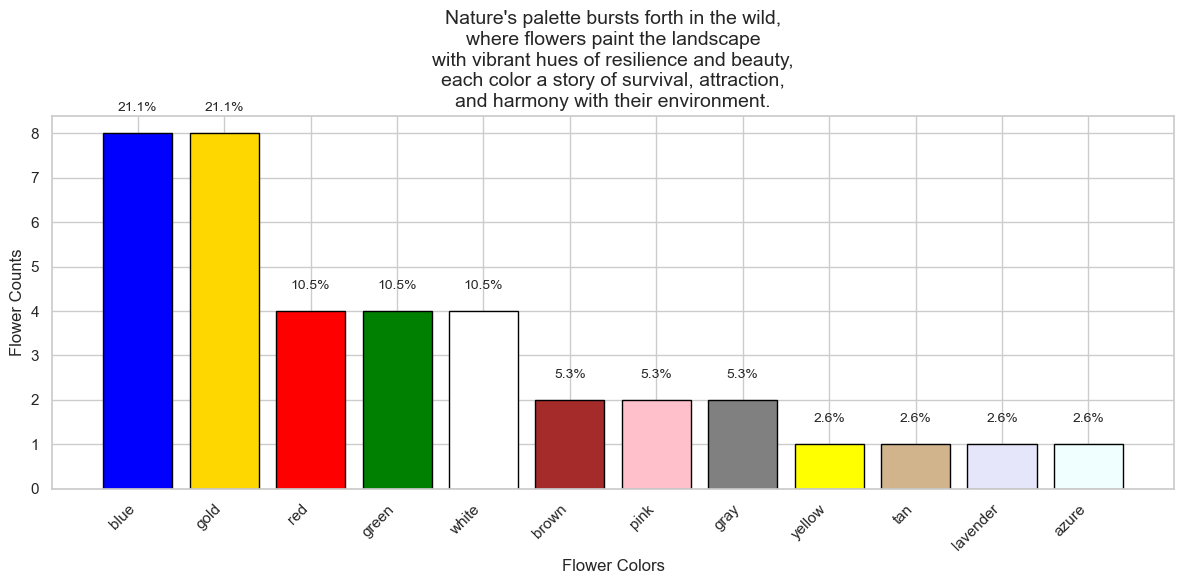

<Figure size 640x480 with 0 Axes>

In [133]:
# 1.2 (6 pts) Extract Flower Color Data
# Create a list of named colors to extract flower colors from description fields in df_flowers.
# A comprehensive set of 148 "named colors" defined by CSS can be found on the W3C CSS Color Module Level.
# The same set of "named colors" is accessible via Python’s matplotlib.colors module or as CSS4_COLORS.
# Use either resource to generate your color list, and ensure color "black" is excluded.
# Add a new column, Color, to df_flowers, populated with a single color extracted from the relevant description, summary, or abstract columns.
# Display the shape of the updated DataFrame and a preview of the first few rows to confirm this step's completion.
colors = list(matplotlib.colors.CSS4_COLORS.keys())
colors.remove('black')

def extract_color(text):
    text = str(text).lower()
    for color in colors:
        if color in text:
            return color
    return "unknown"

df_flowers["Colors"] = df_flowers["Summary"].apply(extract_color)

print(df_flowers.shape)
df_flowers.head()

# 1.3 (8 pts) Generate Vertical Bar Chart
# Key Requirements:
# X-Axis:  Represents flower colors, sorted by count in descending order.  Rotate labels if necessary for better readability.
# Y-Axis:  Represents the count of flowers for each color.
# Annotations:  Display the percentage of each color's count above the corresponding bar.  Ensure the text is clear and appropriately positioned.
# Color Matching:  Ensure the bar colors match the corresponding flower colors.
# Title and Description:  Instead of a typical title, add a brief, descriptive sentence highlighting the connection between flower colors and nature,
# as shown in the example chart. You may use the provided sentence if desired.
# Hints:

# Use Matplotlib or Seaborn to create the chart.
# Generate a custom color palette from the “named colors” list created in Task 1.2 to ensure accurate representation.
# Calculate the percentage for each color based on the total number of flowers (100) in your dataset.

color_counts = df_flowers["Colors"].value_counts()
color_counts = color_counts.sort_values(ascending=False)

total = len(df_flowers)
percentages = (color_counts / total) * 100

plt.figure(figsize=(12, 6))

bars = plt.bar(
    color_counts.index,
    color_counts.values,
    color=color_counts.index,
    edgecolor='black'
)


for i, value in enumerate(color_counts.values):
    plt.text(
        i,
        value + 0.5,
        f"{percentages.iloc[i]:.1f}%",
        ha='center',
        fontsize=10
    )

plt.xticks(rotation=45, ha='right')

plt.title("""Nature's palette bursts forth in the wild,
where flowers paint the landscape
with vibrant hues of resilience and beauty,
each color a story of survival, attraction,
and harmony with their environment.""", fontsize=14)

plt.xlabel("Flower Colors")
plt.ylabel("Flower Counts")

plt.tight_layout()
plt.show()


# 1.4 (3 pts) Save Plot
# Save the vertical bar chart as a PNG file.
# Ensure this file is included in your final submission package.
plt.savefig("verticalBar.png", dpi=300, bbox_inches='tight')



# Deliverables:
# Submit the Python code used to create the vertical bar chart along with the resulting plot saved as a PNG file.

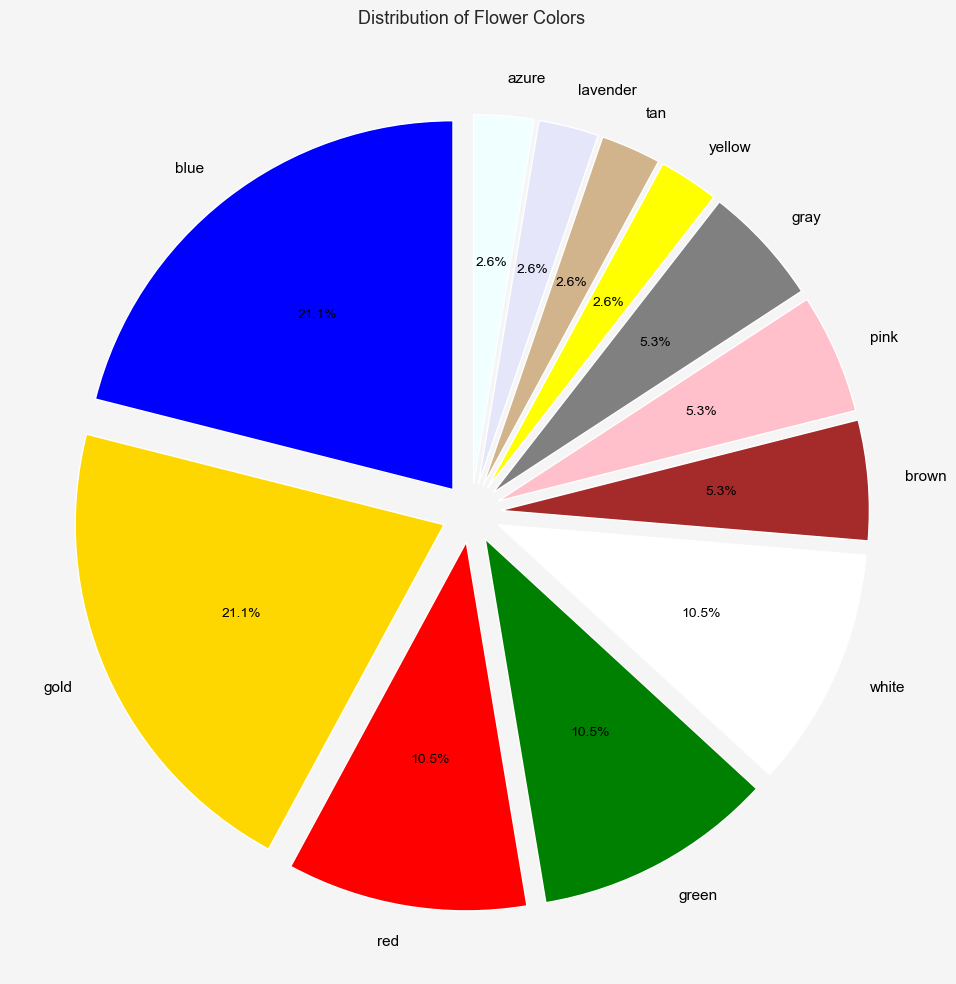

<Figure size 640x480 with 0 Axes>

In [135]:
# Author: Tristin Webb
# Created on: 12/1/2025
# Course: CS454 Python Programming II
# Lab11: Exploring Patterns and Insights in Flower Data with Visualizations
# Objective: Recreate a pie chart showing the percentage distribution of flower colors in your dataset.

# Task 2: Pie Chart – Distribution of Flower Colors (20 points)

# 2.1 (17 pts) Generate Pie Chart
# Key Requirements:
# Proportional Wedges:  The size of each wedge must accurately reflect the relative proportion of each flower color in the dataset.
# Annotations: Display the color name and its percentage either on or near the corresponding wedge. Adjust label placement to prevent overlapping, 
# especially for smaller wedges.
# Exploding Wedges:  Slightly separate smaller wedges (e.g., colors with <1% of the total) to improve visibility and clarity.  Avoid label overlap
# as much as possible.
# Color Matching:  Ensure each wedge is colored accurately using the custom color palette created in Task 1.2.
# Background and Aesthetic:  Use a visually appealing font and color scheme. Ensure labels are legible and provide sufficient contrast with the 
# background.

# Hints:
# Use Matplotlib’s plt.pie() function to create the chart.
# Calculate percentages for each flower color using the counts derived in Task 1.
# Use the explode parameter in plt.pie() to separate smaller wedges for better clarity.
# Use the autopct parameter or manual annotations to display percentages.


color_counts = df_flowers["Colors"].value_counts()
total = len(df_flowers)

percentages = (color_counts / total) * 100

explode = [
    0.08 if p < 25 else 0
    for p in percentages
]

wedge_colors = color_counts.index

plt.figure(figsize=(10, 10), facecolor="#f5f5f5")

wedges, texts, autotexts = plt.pie(
    color_counts.values,
    labels=color_counts.index,
    autopct=lambda pct: f"{pct:.1f}%" if pct > 1 else "",
    explode=explode,
    colors=wedge_colors,
    startangle=90,
    textprops={'fontsize': 11, 'color': 'black'}
)

for autotext in autotexts:
    autotext.set_color("black")
    autotext.set_fontsize(10)

plt.title(
    "Distribution of Flower Colors",
    fontsize=13,
    pad=20
)

plt.tight_layout()
plt.show()

    
# 2.2 (3 pts) Save Plot
# Save the pie chart as a PNG file.
# Ensure this file is included in your final submission package.
plt.savefig("pieChart.png", dpi=300, bbox_inches='tight')


# Deliverables:
# Submit the Python code used to create the pie chart along with the resulting plot saved as a PNG file.

(38, 9)


C:\Users\lunix\AppData\Local\Temp\ipykernel_30692\2581697799.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


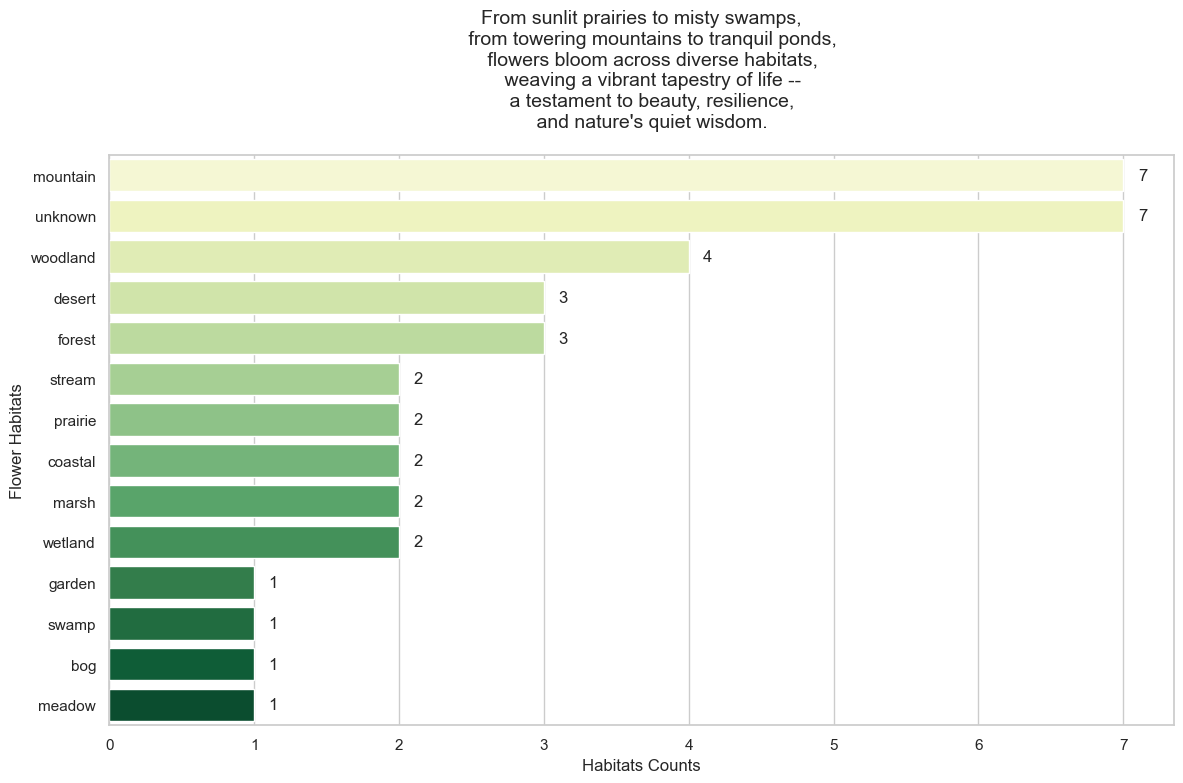

<Figure size 640x480 with 0 Axes>

In [137]:
# Author: Tristin Webb
# Created on: 12/1/2025
# Course: CS454 Python Programming II
# Lab11: Exploring Patterns and Insights in Flower Data with Visualizations
# Objective: Recreate a horizontal bar chart visualizing the distribution of flower habitats in your dataset.

# Task 3: Horizontal Bar Chart – Flower Habitats (20 points)

# 3.1 (10 pts) Extract Flower Habitat Data
# Generate a Habitat List: Create a comprehensive list of habitat names to extract habitat information from the description fields in df_flowers.
# To build this list, visit Wikipedia’s Habitat page and manually compile habitat names.
# Explore similar resources to identify additional synonyms for habitats.
# Aim to build a list of approximately 100 habitat names to ensure thorough extraction.
# Add a Habitat Column: Add a new column, Habitat, to df_flowers by extracting a single habitat mentioned in the description, summary, or abstract
# columns.
# Verify Extraction: Display the shape of the updated DataFrame and preview the first few rows to confirm the new column has been added correctly.
habitats = [
    "forest", "rainforest", "tropical forest", "woodland",
    "grassland", "prairie", "savanna", "steppe",
    "desert", "semi-desert",
    "wetland", "marsh", "swamp", "bog", "fen",
    "mountain", "alpine", "montane", "highland",
    "coastal", "beach", "dune", "shoreline",
    "riverbank", "river", "stream", "creek", "riparian",
    "lake", "pond",
    "meadow", "field",
    "scrubland", "shrubland",
    "tundra", 
    "urban", "garden", "park"
]

habitats = [h.lower() for h in habitats]

def extract_habitat(text):
    text = str(text).lower()
    for h in habitats:
        if h in text:
            return h
    return "unknown"

df_flowers["Habitat"] = df_flowers["Summary"].apply(extract_habitat)

print(df_flowers.shape)
df_flowers.head()

    
# 3.2 (7 pts) Generate Horizontal Bar Chart
# Key Requirements:
# Y-Axis: Display flower habitats, sorted by count in descending order. Ensure all habitat names are fully visible and not truncated.
# X-Axis: Show the count of flowers for each habitat.
# Bar Style: Use a gradient or earthy palette to visually reflect natural tones.
# Title and Aesthetic: Include a meaningful title that describes the chart's purpose or add a poetic or descriptive phrase in the blank space beneath 
# the chart, emphasizing the diversity of flower habitats. (You may use the provided phrase if preferred.)
# Annotations (Optional): Include data labels or annotations showing the exact counts next to each habitat bar. Ensure annotations do not clutter the
# chart.
# Hints:

# Use Matplotlib or Seaborn to create the horizontal bar plot (sns.barplot or plt.barh).
# Count the values in the Habitat column to determine the frequency of each habitat in the dataset.
# Adjust figure dimensions and label spacing for clarity and readability.


habitat_counts = df_flowers["Habitat"].value_counts()

palette = sns.color_palette("YlGn", len(habitat_counts))

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    x=habitat_counts.values,
    y=habitat_counts.index,
    palette=palette
)

for i, v in enumerate(habitat_counts.values):
    plt.text(v + 0.1, i, str(v), va='center')

plt.title(
    """From sunlit prairies to misty swamps,
    from towering mountains to tranquil ponds,
    flowers bloom across diverse habitats,
    weaving a vibrant tapestry of life --
    a testament to beauty, resilience,
    and nature's quiet wisdom.""",
    fontsize=14,
    pad=20
)

plt.xlabel("Habitats Counts")
plt.ylabel("Flower Habitats")

plt.tight_layout()
plt.show()


# 3.3 (3 pts) Save Plot
# Save the horizontal bar chart as a PNG file.
# Ensure this file is included in your final submission package.
plt.savefig("horizontalBar.png", dpi=300, bbox_inches='tight')


# Deliverables:
# Submit the Python code used to create the horizontal bar chart along with the resulting plot saved as a PNG file.

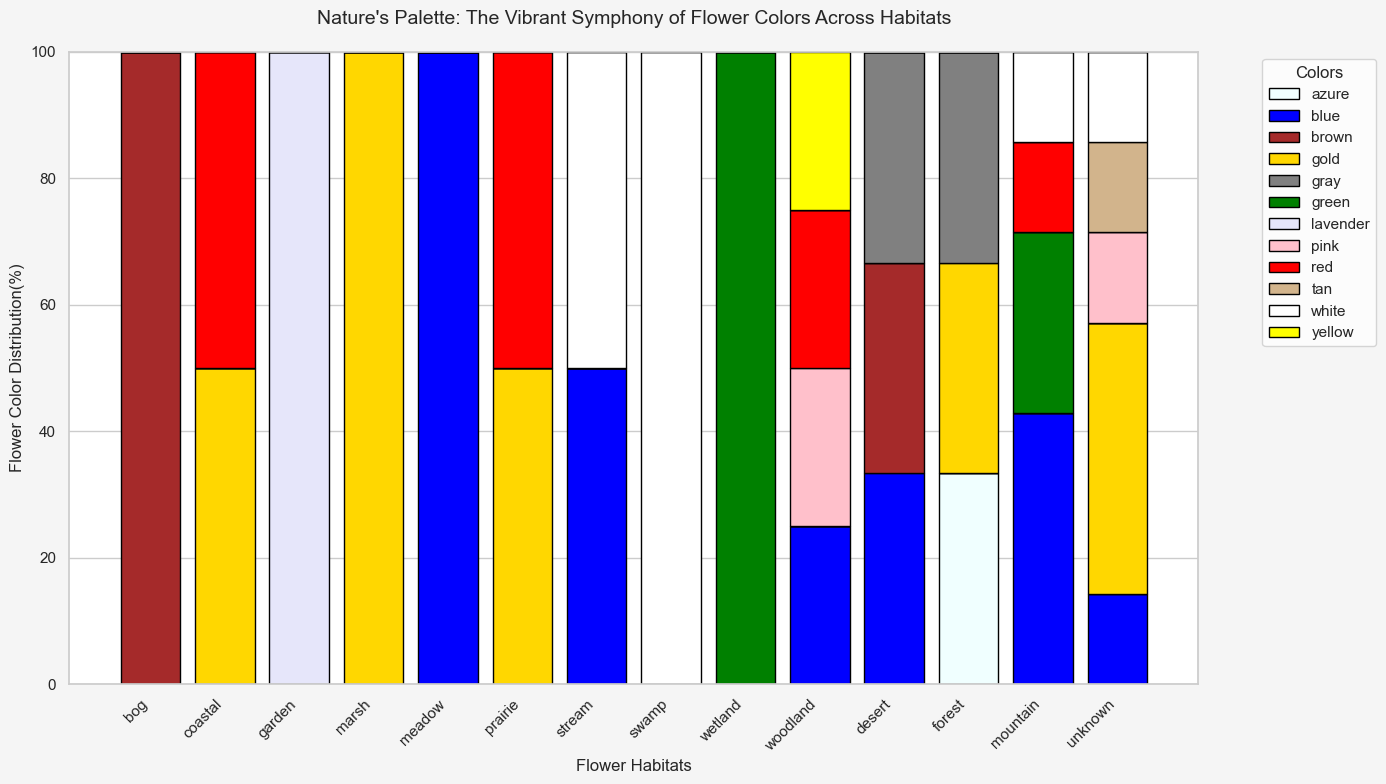

<Figure size 640x480 with 0 Axes>

In [138]:
# Author: Tristin Webb
# Created on: 12/1/2025
# Course: CS454 Python Programming II
# Lab11: Exploring Patterns and Insights in Flower Data with Visualizations
# Objective: Recreate a stacked bar chart showing the percentage distribution of flower colors within different habitats.

# Task 4: Stacked Bar Chart – Flower Color Distribution Across Habitats (20 points)
# 4.1 (17 pts) Generate Stacked Bar Chart
# Key Requirements:
# X-Axis: Display flower habitats. Rotate the labels to improve readability.
# Y-Axis: Show the percentage distribution (0–100%).
# Stacked Bars: Each bar represents a habitat, and is divided into stacked sections for each flower color. The height of each section corresponds
# to the percentage of that color in the habitat.
# Custom Palette: Use your custom color palette from Task 1.2 to ensure each flower color is accurately represented.
# Legend: Include a clear legend mapping each flower color to its corresponding bar section.
# Background and Aesthetics: Use an appropriate background color and professional font for a polished appearance.  Add a descriptive title that
# reflects the theme of color diversity across habitats.
# Hints:

# Use pd.crosstab() or a similar method to compute the percentage distribution of flower colors across habitats.
# Normalize the data row-wise to calculate percentages for each flower color within each habitat.
# Use Matplotlib or Seaborn to create a stacked bar chart.
# Use sns.barplot() or Matplotlib’s ax.bar() with the bottom parameter to stack the bars.

habitat_color_counts = pd.crosstab(df_flowers["Habitat"], df_flowers["Colors"])

habitat_color_pct = habitat_color_counts.div(habitat_color_counts.sum(axis=1), axis=0) * 100

habitat_color_pct = habitat_color_pct.loc[habitat_color_pct.sum(axis=1).sort_values(ascending=False).index]

color_list = habitat_color_pct.columns.tolist() 

plt.figure(figsize=(14, 8), facecolor="#f5f5f5") 

bottom_vals = pd.Series([0]*len(habitat_color_pct), index=habitat_color_pct.index)

for color in color_list:
    plt.bar(
        habitat_color_pct.index,
        habitat_color_pct[color],
        bottom=bottom_vals,
        color=color,
        edgecolor="black",
        label=color
    )
    bottom_vals += habitat_color_pct[color]

plt.ylabel("Flower Color Distribution(%)")
plt.xlabel("Flower Habitats")
plt.xticks(rotation=45, ha='right')
plt.title(
    "Nature's Palette: The Vibrant Symphony of Flower Colors Across Habitats",
    fontsize=14,
    pad=20
)

plt.legend(title="Colors", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


    
# 4.2 (3 pts) Save Plot
# Save the stacked bar chart as a PNG file.
# Ensure this file is included in your final submission package.
plt.savefig("stackedChart.png", dpi=300, bbox_inches='tight')


# Deliverables:
# Submit the Python code used to create the stacked bar chart along with the resulting plot saved as a PNG file.

In [ ]:
# Author: Tristin Webb
# Created on: 12/1/2025
# Course: CS454 Python Programming II
# Lab11: Exploring Patterns and Insights in Flower Data with Visualizations
# Objective: Recreate a scatter plot to explore the relationship between flower petal length and width using synthetic data.

# Task 5: Scatter Plot – Petal Length vs. Width (20 points)

# 5.1 (7 pts) Generate Synthetic Data for Flower Petal Dimensions
# Add synthetic data for petal length and petal width to your flower dataset. The generated data should exhibit a realistic correlation between 
# petal length and width.
# Generate Synthetic Data: Create two new columns in df_flowers: petal_length and petal_width. Use NumPy’s random number generator to populate 
# these columns with synthetic values.
# Petal Length: Randomly generate values between 3 cm and 12 cm.
# Petal Width: Generate values proportional to petal length using a formula (e.g., width = 0.2 * length + noise), where noise is a small random 
# variation to add realism.
# Ensure Realistic Correlation: Design the data so it reflects a strong positive correlation between length and width (e.g., correlation 
# coefficient ≥ 0.6). This can be achieved by basing petal_width on petal_length.
# Add to Dataset: Add the petal_length and petal_width columns to the df_flowers DataFrame. Ensure each flower has corresponding length 
# and width values.
# Save the Dataset:  Save the updated dataset as flowers_data.csv for submission with your solution package.
# Hints:

# Use one of NumPy's random number generation functions to create the synthetic data.
# E.g.: np.random.uniform(low, high, size) generates random float values between 'low' and 'high' with a specified 'size'.
# Use mathematical operations (e.g., scaling and addition) to create a dependency between petal_length and petal_width.
# Add random noise to petal_width to preserve the correlation while making the data more realistic.

np.random.seed(42)

n_flowers = len(df_flowers)

df_flowers['petal_length'] = np.random.uniform(3, 12, size=n_flowers)


noise = np.random.normal(0, 0.5, size=n_flowers) 
df_flowers['petal_width'] = 0.2 * df_flowers['petal_length'] + noise

df_flowers['petal_width'] = df_flowers['petal_width'].clip(lower=0.5)

correlation = df_flowers['petal_length'].corr(df_flowers['petal_width'])
print(f"Correlation coefficient between petal length and width: {correlation:.2f}")

df_flowers.to_csv("flowers_data.csv", index=False)

    
# 5.2 (10 pts) Generate Scatter Plot
# Key Requirements:
# X-Axis:  Represent flower petal length (cm).
# Y-Axis:  Represent flower petal width (cm).
# Points:  Each flower is represented as a point on the plot, with colors assigned based on its habitat using a consistent color palette.
# Regression Line:  Add a linear regression line to visualize the trend between length and width. Annotate the plot with the correlation 
# coefficient (e.g., "Correlation Coefficient: 0.80").
# Legend:  Include a legend mapping colors to habitats, positioned to avoid overlapping with the data points.
# Aesthetics:  Add a descriptive title reflecting the harmony of petal dimensions.  Use a professional font style and annotate the correlation
# coefficient in a contrasting color for emphasis.
# Background:  Use a subtle background color to enhance readability and visual appeal.
# Hints:

# Use Seaborn’s sns.scatterplot and sns.regplot to create the scatter plot and regression line, or Matplotlib's plt.plot for customization.
# Calculate the correlation coefficient using numpy or pandas and annotate it using plt.text.
# Set point transparency (alpha) to make overlapping points more distinguishable.


sns.set(style="whitegrid")

habitat_palette = sns.color_palette("tab10", len(df_flowers['Habitat'].unique()))
habitat_colors = dict(zip(df_flowers['Habitat'].unique(), habitat_palette))

plt.figure(figsize=(10, 7), facecolor="#f5f5f5")

sns.scatterplot(
    data=df_flowers,
    x='petal_length',
    y='petal_width',
    hue='Habitat',
    palette=habitat_colors,
    alpha=0.8,
    s=100
)

sns.regplot(
    data=df_flowers,
    x='petal_length',
    y='petal_width',
    scatter=False,
    color='black',
    line_kws={'linewidth':2, 'linestyle':'--'}
)


plt.xlabel("Flower Petal Length (cm)")
plt.ylabel("Flower Petal Width (cm)")
plt.title("Nature's elegance emerges in the harmony between petal length and width", fontsize=14, pad=20)

plt.legend(title="Habitat", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()


plt.show()


# 5.3 (3 pts)  Save Data and Plot Files
# Save the updated df_flowers containing synthetic petal length and width data as a CSV file.
# Save the scatter plot as a PNG file.
# Ensure both the CSV and PNG files are included in your final submission package.
df_flowers.to_csv("flowers_data.csv")

plt.savefig("scatterChart.png", dpi=300, bbox_inches='tight')


# Deliverables:
# Submit the Python code, the updated dataset with synthetic data (saved as a CSV file), and the resulting scatter plot as a PNG file.

Correlation coefficient between petal length and width: 0.81
